<div style="background-color: #f5f8fb; border-left: 5px solid #277da8; padding: 16px 20px; margin-bottom: 18px; border-radius: 4px;">
<p style="color: #46586b; font-size: 12px; font-weight: 600; letter-spacing: 1px; margin: 0 0 7px 0;">INVESTIGACIÓN DE OPERACIONES</p>
<h1 style="color: #14283f; font-size: 29px; line-height: 1.3; margin: 0;">CADENAS ABSORBENTES</h1>
</div>

## <span style="color: #277da8;">Ejercicio 1</span>

Se coloca una **rata blanca** en el laberinto que se muestra:

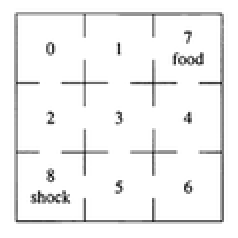

En ausencia de aprendizaje, cabría suponer que la rata se desplaza por el laberinto de forma **aleatoria**; es decir, si existen $k$ posibles salidas desde un compartimento, la rata elige cada una de ellas con probabilidad **$1/k$**.

En cada unidad de tiempo, la rata se traslada a un compartimento adyacente. Sea $X_n$ el compartimento ocupado en el instante $n$.

El **compartimento 7** contiene <span style="color: #277da8;"><strong>comida</strong></span> y en el **8** hay un mecanismo de <span style="color: #a85d2a;"><strong>descargas eléctricas</strong></span>.

**¿Cuál es la probabilidad de que la rata, al moverse aleatoriamente, encuentre la comida antes de recibir una descarga?**

In [1]:
import numpy as np
from numba import njit

# Parámetros de la simulación.
N = 1_000_000
semilla = 20261102
# Uso un flujo aleatorio para cada inicio y otro para el tablero.
flujos = np.random.SeedSequence(semilla).spawn(8)

# Puertas disponibles en cada compartimento.
vecinos = np.array([
    [1, 2, -1, -1],
    [0, 3, 7, -1],
    [0, 3, 8, -1],
    [1, 2, 4, 5],
    [3, 6, 7, -1],
    [3, 6, 8, -1],
    [4, 5, -1, -1]
])
# Cuento las puertas disponibles en cada compartimento.
grados = np.sum(vecinos >= 0, axis=1)

@njit
def simular_laberinto(inicio, n, rng):
    comidas = 0

    for _ in range(n):
        x = inicio

        while x < 7:
            puerta = rng.integers(0, grados[x])
            x = vecinos[x, puerta]

        if x == 7:
            comidas += 1

    return comidas / n

### <span style="color: #a85d2a;">Probabilidad estimada y comparación</span>

Repito **$N=1\,000\,000$ recorridos por inicio**. Cuento cuántos terminan en comida y divido entre el total:

$$\widehat p=\frac{\text{recorridos que terminan en 7}}{N}.$$

Comparo la frecuencia simulada con las probabilidades analíticas, en el orden $0,1,\ldots,6$:

$$\mathbf p=\left(\frac12,\frac23,\frac13,\frac12,\frac23,\frac13,\frac12\right)^{\mathsf T}.$$

Con el **error estándar Monte Carlo** mido la variación de la estimación:

$$\operatorname{EE}(\widehat p)\approx\sqrt{\frac{\widehat p(1-\widehat p)}{N}}.$$

In [2]:
# El enunciado no fija el inicio: repito N recorridos desde cada estado 0,...,6.
p_simulada = np.array([
    simular_laberinto(i, N, np.random.default_rng(flujos[i])) for i in range(7)
])
p_teorica = np.array([1/2, 2/3, 1/3, 1/2, 2/3, 1/3, 1/2])
error_p = np.sqrt(p_simulada * (1 - p_simulada) / N)

print("Orden de los inicios: 0, 1, 2, 3, 4, 5, 6")
print("Probabilidad simulada:", np.round(p_simulada, 6))
print("Probabilidad teórica: ", np.round(p_teorica, 6))
print("Error estándar MC:    ", np.round(error_p, 6))
print(f"Desde 0: {p_simulada[0]:.6f}; valor exacto: 0.5.")

Orden de los inicios: 0, 1, 2, 3, 4, 5, 6
Probabilidad simulada: [0.499697 0.666402 0.33385  0.499441 0.66658  0.333483 0.499757]
Probabilidad teórica:  [0.5      0.666667 0.333333 0.5      0.666667 0.333333 0.5     ]
Error estándar MC:     [0.0005   0.000471 0.000472 0.0005   0.000471 0.000471 0.0005  ]
Desde 0: 0.499697; valor exacto: 0.5.


**Interpreto el resultado:** desde 0 obtengo una probabilidad cercana a
<span style="color: #277da8;"><strong>$1/2$</strong></span>.
Como el enunciado no fija el inicio, conservo los siete resultados y uso la entrada que corresponde a cada compartimento.

## <span style="color: #277da8;">Ejercicio 2</span>

Si el juego comienza en la **casilla 1** y termina al alcanzar la **casilla 20 (sin retorno)**, para el tablero mostrado y un **dado ordinario**:

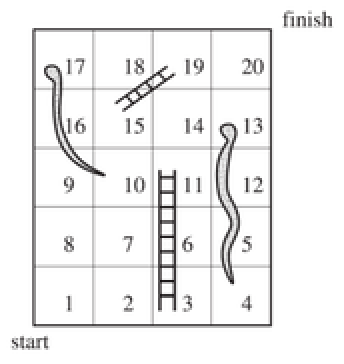

**¿cuál es el número esperado de tiradas para terminar un juego solitario?**

In [3]:
# Interpreto "sin retorno" como terminar al alcanzar o rebasar 20.
@njit
def simular_tablero(n, rng):
    tiradas = np.zeros(n, dtype=np.int64)

    for j in range(n):
        x = 1

        while x < 20:
            x += rng.integers(1, 7)  # Genero una cara del dado.
            if x == 3:
                x = 11
            elif x == 15:
                x = 19
            elif x == 13:
                x = 4
            elif x == 17:
                x = 10
            tiradas[j] += 1

    return tiradas

### <span style="color: #a85d2a;">Promedio de tiradas y comparación</span>

Repito **$N=1\,000\,000$ partidas completas**. Si $T_j$ es la duración de la partida $j$, calculo

$$\overline T=\frac1N\sum_{j=1}^{N}T_j.$$

Comparo este promedio con la esperanza analítica para **alcanzar o rebasar 20**:

$$\mathbb E[T]=\frac{44898302749}{6508559952}\approx6.898346651.$$

Uso la desviación estándar muestral $s_T$ para calcular el error Monte Carlo y un intervalo aproximado al 95%:

$$\operatorname{EE}(\overline T)\approx\frac{s_T}{\sqrt N},\qquad
\overline T\pm1.96\,\frac{s_T}{\sqrt N}.$$

In [4]:
# Promedio las duraciones de N partidas completas.
tiradas = simular_tablero(N, np.random.default_rng(flujos[7]))
media = np.mean(tiradas)
media_teorica = 44898302749 / 6508559952
error_media = np.std(tiradas, ddof=1) / np.sqrt(N)
intervalo = media + np.array([-1, 1]) * 1.96 * error_media

print(f"Media simulada: {media:.6f} tiradas.")
print(f"Media teórica:  {media_teorica:.6f} tiradas.")
print(f"Diferencia absoluta: {abs(media - media_teorica):.6f}.")
print(f"Error estándar MC: {error_media:.6f}.")
print("IC 95% aproximado:", np.round(intervalo, 6))

Media simulada: 6.894569 tiradas.
Media teórica:  6.898347 tiradas.
Diferencia absoluta: 0.003778.
Error estándar MC: 0.003189.
IC 95% aproximado: [6.888318 6.90082 ]


**Interpreto el resultado:** el juego necesita alrededor de
<span style="color: #277da8;"><strong>6.9 tiradas en promedio</strong></span>.
El intervalo describe la incertidumbre de la media estimada, no la duración de una partida individual.

<span style="color: #a85d2a;"><strong>Regla de llegada.</strong></span>
Si debo llegar exactamente a 20 y permanecer en la casilla cuando el dado sobra, la esperanza analítica cambia a **11.435347 tiradas**.
La simulación anterior usa la regla de alcanzar o rebasar 20.